## Clasificación de Cáncer de Mama con Redes Neuronales Artificiales

---

 Aplicar redes neuronales utilizando scikit-learn para clasificar tumores del Winsconsin Breast Cancer Dataset y analizar el impacto de distintas arquitecturas en el desempeño, la generalización y el tiempo de procesamiento.

### Preliminares
- importar las dependencias.
- definir constantes.

In [253]:
import time as tm

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler


In [254]:
SEED = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.25 # 25% del subconjunto (train, validation), no del total.
MAX_EPOCH = 2000
ARCH_A = (10,)
ARCH_B = (30,15)
ARCH_C = (100,50,25,10)


### Parte 1:
- cargar el dataset.
- mostrar número de muestras, características y ditribución de clases.
- realizar descripción del conjunto de datos.

In [255]:
data = load_breast_cancer()
x, y = data.data, data.target


resumen = pd.DataFrame({
    "Métrica": ["Cantidad de muestras", "Cantidad de características", "Clases", "Cantidad de muestras por clase"],
    "Valor": [x.shape[0], x.shape[1], ", ".join(data.target_names), ", ".join(np.bincount(y).astype(str))]
})

resumen 

,Métrica,Valor
0,Cantidad de muestras,569
1,Cantidad de características,30
2,Clases,"malignant, benign"
3,Cantidad de muestras por clase,"212, 357"


El dataset que nos ofrece `load_breast_cancer()` contienen datos sobre los diagnosticos de cancer de mama de Wisconsin.  
En total se tienen `569` muestras de tumor, de las cuales `212` son `malignas` y `357` son `benignas`. Ademas, este dataset contiene `30` caracteristicas  
como textura, perimetro, concavidad, simetria, etc.

### Parte 2:
- Dividir aleatoria y estratificadamente el dataset en Train (60%), Validation (20%) y Test (20%).

In [268]:
x_train_and_validation, x_test, y_train_and_validation, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
x_train, x_validation, y_train, y_validation = train_test_split(x_train_and_validation, y_train_and_validation, test_size=VALIDATION_SIZE, random_state=SEED, stratify=y_train_and_validation)

### Parte 3:
- Ajustar StandardScaler únicamente con Train.
- Transformar Train, Validation y Test.

In [257]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_validation_scaled = scaler.transform(x_validation)
x_test_scaled = scaler.transform(x_test)

### Parte 4:
Definir las arquitecturas a evaluar
- Configuración A: hidden_layer_sizes=(10,)
- Configuración B: hidden_layer_sizes=(30,15)
- Configuración C: hidden_layer_sizes=(100,50,25,10)

In [258]:
mlp_A = MLPClassifier(hidden_layer_sizes=ARCH_A, max_iter=MAX_EPOCH, random_state=SEED, early_stopping=False)
mlp_B = MLPClassifier(hidden_layer_sizes=ARCH_B, max_iter=MAX_EPOCH, random_state=SEED, early_stopping=False)
mlp_C = MLPClassifier(hidden_layer_sizes=ARCH_C, max_iter=MAX_EPOCH, random_state=SEED, early_stopping=False)

### Parte 5:
- Entrenar cada arquitectura usando únicamente Train.
- Medir tiempo de entrenamiento.
- Evaluar sobre Validation.
- Calcular Accuracy.
- Obtener matriz de confusión.
- Registrar resultados en una tabla comparativa.

In [259]:
def train_MLP(mlp):
  start_time = tm.time()
  mlp.fit(x_train_scaled, y_train)
  train_time = tm.time() - start_time

  y_predicted = mlp.predict(x_validation_scaled)
  accuracy = accuracy_score(y_validation, y_predicted)
  cm = confusion_matrix(y_validation, y_predicted)

  return train_time, accuracy, cm

In [260]:
train_time_A, accuracy_A, confusion_matrix_A = train_MLP(mlp_A)
train_time_B, accuracy_B, confusion_matrix_B = train_MLP(mlp_B)
train_time_C, accuracy_C, confusion_matrix_C = train_MLP(mlp_C)

In [261]:
data_table = {
  "Configuración":           ['A',             "B",             "C",],
  "Arquitectura":            [ARCH_A,           ARCH_B,          ARCH_C],
  "Tiempo de entrenamiento": [train_time_A,    train_time_B,    train_time_C],
  "Exactitud":               [accuracy_A,      accuracy_B,      accuracy_C],
  "Iteraciones":             [mlp_A.n_iter_,   mlp_B.n_iter_,   mlp_C.n_iter_],
  "Capas":                   [mlp_A.n_layers_, mlp_B.n_layers_, mlp_C.n_layers_]
}

pd.DataFrame(data_table)

,Configuración,Arquitectura,Tiempo de entrenamiento,Exactitud,Iteraciones,Capas
0,A,"(10,)",0.167730,0.982456,369,3
1,B,"(30, 15)",0.144636,0.973684,233,4
2,C,"(100, 50, 25, 10)",0.133163,0.956140,102,6


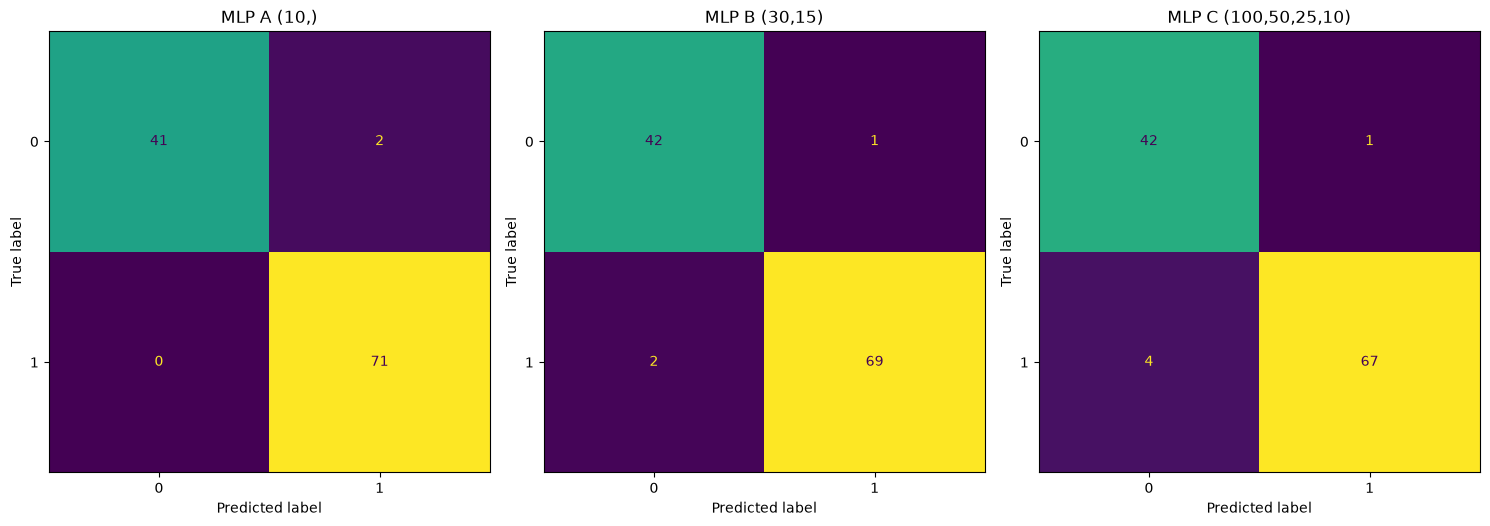

In [262]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

ConfusionMatrixDisplay(confusion_matrix_A).plot(ax=axes[0], colorbar=False)
axes[0].set_title('MLP A (10,)')

ConfusionMatrixDisplay(confusion_matrix_B).plot(ax=axes[1], colorbar=False)
axes[1].set_title('MLP B (30,15)')

ConfusionMatrixDisplay(confusion_matrix_C).plot(ax=axes[2], colorbar=False)
axes[2].set_title('MLP C (100,50,25,10)')

plt.tight_layout()
plt.show()

### Parte 6:
  - Seleccionar la mejor arquitectura considerando Accuracy, tiempo y complejidad.
  - Justificar la decisión.

#### Decisión: **Configuración A**

##### Justificación

Después de entrenar y ver los resultados de cada entrenamiento he decidido que la mejor configuración es la **Configuración A**.  
La decisión la tomé a partir de los resultados obtenidos, donde a pesar de haber tenido un mayor tiempo de entrenamiento (aunque mínimo) respecto a las demás configuraciones, es la configuración que más exactitud ha obtenido por encima de las demás y además es la que tiene una complejidad menor con solo 10 neuronas en la capa oculta.

---

Es interesante mencionar varios aspectos que he descubierto durante el entrenamiento y selección de la mejor configuración:
1. La observación mas clara es que justamente como se esperaba, la configuración más compleja (con más capas ocultas) **no significa que deba tener un mejor desempeño ni una mejor exactitud**.

2. A pesar de que la configuración A requiere de mas épocas para converger (**369**) que las demás configuraciones (233 y 102), los tiempos de entrenamiento son muy similares,
   esto debido a que una época de A es **computacionalmente más barata** que una época de C, donde hay más parámetros que actualizar. Es decir, que **más épocas no significa más tiempo.**

3. El hecho de que la configuración C tenga la menor cantidad de épocas pero también la peor exactitud es un indicio de un sobreajuste donde el modelo converge muy rápido ya que al tener muy pocos datos  
   pero una gran capacidad, memoriza los datos casi de forma inmediata. Al no haber cambios en el gradiente descendiente durante las épocas, `scikit-learn` mediante la variable `n_iter_no_change` rompe las iteraciones parando de forma temprana el aprendizaje.

4. He descubierto que si bien como lo mencione en el punto 2 los tiempos de entrenamiento son similares, esto depende mucho del hardware en el que se entrene el modelo. Para validar mi hipótesis, he ejecutado el mismo archivo sin ninguna modificación en tres entornos distintos:**Google Colab**, **Deepnote** y **Kaggle Notebooks**. En cada uno los tiempos de entrenamiento han variado han variado bastante respecto a mi ejecución local, sin embargo, **las iteraciones, épocas y la exactitud se ha mantenido exactamente igual**. Esto significa que el **tiempo de entrenamiento no es una métrica muy fiable** y que depende mucho del hardware donde se ejecute, especialmente si hay una gran cantidad de nucleos/hilos disponibles en la CPU (`scikit-learn` no puede correr en GPU porque no esta optimizada).

5. Dicho lo anterior, en los entornos remotos en los que he ejecutado el código si que se observa el patrón "esperado" de una configuración simple (A) y una compleja (C) respecto a los tiempos de entrenamiento, donde la configuración C requiere de mayor tiempo y la configuración C bastante menos. Sin embargo, esto reafirma aún más el punto 2, ya que cada época de C es **bastante más costosa** computacionalmente, como cabría esperar de una red con muchos más parámetros.

### Parte 7:
- Unir Train y Validation.
- Reentrenar la mejor arquitectura.
- Evaluar sobre Test.
- Reportar Accuracy final, matriz de confusión y tiempo final.

In [263]:
x_train_val = np.vstack((x_train_scaled, x_validation_scaled))
y_train_val = np.hstack((y_train, y_validation))

In [264]:
final_mlp = MLPClassifier(hidden_layer_sizes=ARCH_A, max_iter=MAX_EPOCH, random_state=SEED)

start_time = tm.time()
final_mlp.fit(x_train_val, y_train_val)
final_train_time = tm.time() - start_time

final_y_predicted = final_mlp.predict(x_test_scaled)
final_accuracy = accuracy_score(y_test, final_y_predicted)
final_confusion_matrix = confusion_matrix(y_test, final_y_predicted)

In [265]:
data_table = {
  "Configuración":           ['Final',],
  "Arquitectura":            [ARCH_A],
  "Tiempo de entrenamiento": [final_train_time,],
  "Exactitud":               [final_accuracy,],
  "Iteraciones":             [final_mlp.n_iter_,],
  "Capas":                   [final_mlp.n_layers_,]
}

pd.DataFrame(data_table)

,Configuración,Arquitectura,Tiempo de entrenamiento,Exactitud,Iteraciones,Capas
0,Final,"(10,)",0.188613,0.964912,308,3


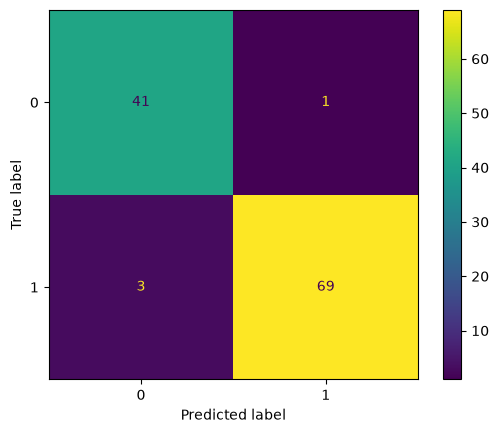

In [266]:
ConfusionMatrixDisplay(final_confusion_matrix).plot()
plt.show()